# Evaluating Adaptive Churn Prediction Under Temporal Customer-Behavior Drift (v2)

This notebook follows the **updated proposal** (Nadeem & Majid, 6 Oct 2026) step by step. Every rule is in `churn_core.py` (STEP 2), with the proposal section next to it.

- Eligible customer at date *t*: at least one purchase in [t − 180 days, t)
- Label: y = 1 if **no purchase in [t, t + 60 days)** (primary); 90 days as sensitivity
- Monthly snapshots from 1 June 2010; tuning at 1 Oct 2010; frozen before 1 Jan 2011
- Common initial fit on 1 Jan 2011 (latest 5 fully labelled snapshots); fixed vs monthly retrained (latest 5 mature snapshots)
- Nine test dates 1 Jan – 1 Sep 2011; primary endpoint = mean of nine XGBoost AP differences with a customer cluster bootstrap

Run the cells from top to bottom (CPU is enough, about 10 minutes).

## STEP 1: download Online Retail II from UCI

In [1]:
import os
if not os.path.exists('online_retail_II.xlsx'):
    !wget -q -O online_retail_ii.zip "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
    !unzip -o -q online_retail_ii.zip
!ls -la online_retail_II.xlsx

-rw------- 1 root root 45622278 May 22  2023 online_retail_II.xlsx


## STEP 2: write the code files (all rules of the proposal)
You do not need to change anything here. Settings are in `SETTINGS` at the top of the file.

In [2]:
%%writefile churn_core.py
"""Adaptive churn study, version 2: follows the updated proposal exactly.

Proposal: "Evaluating Adaptive Churn Prediction Under Temporal Customer-Behavior Drift"
(Alishba Nadeem, Izza Majid, 6 Oct 2026). Section numbers below refer to that proposal.
"""
import time
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

# ------------------------------------------------------------------ fixed settings (Sections 4-7)
SETTINGS = dict(
    LOOKBACK_DAYS=180,              # features and eligibility use [t-180 days, t)
    H_PRIMARY=60,                   # primary outcome horizon (days)
    H_SENSITIVITY=90,               # predefined sensitivity horizon (days)
    FIRST_SNAPSHOT="2010-06-01",    # monthly snapshots start 1 June 2010
    VALIDATION_DATE="2010-10-01",   # tuning snapshot (Section 6, Initial validation)
    FIRST_TEST="2011-01-01",        # common initial fit and first test date
    LAST_TEST="2011-09-01",         # nine test dates: 1 Jan .. 1 Sep 2011
    WINDOW=5,                       # latest 5 fully labelled snapshots
    THRESHOLD=0.5,                  # fixed probability threshold for threshold metrics
    N_BOOT=1000,                    # customer cluster bootstrap replicates
    SEED=42,                        # one recorded seed
    EXPANDING_EXTENSION=False,      # optional extension (Section 8), off for the core analysis
)

FEATURES = ["recency", "frequency", "monetary", "avg_order", "units", "unique_products",
            "inv_30", "spend_30", "inv_60", "spend_60", "inv_change_30", "mean_gap", "gap_missing"]
FEATURE_INFO = {
    "recency": "days since the last purchase before t",
    "frequency": "distinct invoices in the last 180 days",
    "monetary": "gross positive spend in the last 180 days",
    "avg_order": "average order value (spend / invoices)",
    "units": "total units bought in the last 180 days",
    "unique_products": "distinct products (StockCode) in the last 180 days",
    "inv_30": "invoices in the last 30 days",
    "spend_30": "spend in the last 30 days",
    "inv_60": "invoices in the last 60 days",
    "spend_60": "spend in the last 60 days",
    "inv_change_30": "invoices in last 30 days minus invoices in the 30 days before",
    "mean_gap": "mean days between invoices (missing if fewer than 2 invoices)",
    "gap_missing": "1 if the customer has fewer than 2 invoices (mean_gap is missing)",
}
LOG_COLS = ["frequency", "monetary", "avg_order", "units", "unique_products", "spend_30", "spend_60"]  # set before testing
DRIFT_FEATURES = ["recency", "frequency", "monetary"]  # Section 7: RFM shifts vs January cohort

# Section 6: at most six configurations per model family per horizon
GRIDS = {
    "LR": [{"C": c} for c in [0.01, 0.1, 1.0, 10.0]],
    "XGB": [{"max_depth": d, "n_estimators": n, "learning_rate": lr}
            for d in [3, 5] for (n, lr) in [(100, 0.1), (300, 0.05), (500, 0.03)]],
}
MODELS = ["LR", "XGB"]
MODEL_NAMES = {"LR": "Logistic Regression", "XGB": "XGBoost"}

# Section 4: audited numbers quoted in the proposal (used by proposal_check)
QUOTED = {
    "raw rows": 1067371, "missing customer ID excluded": 243007, "remaining identified rows": 824364,
    "after keeping valid purchases": 805549, "after removing exact duplicates": 779425,
    "distinct customers": 5878, "distinct invoices": 36969,
    "gap median (days)": 20.95, "gap 75th pct (days)": 49.08, "gap 90th pct (days)": 90.96,
    "60-day prevalence min (%)": 50.94, "60-day prevalence max (%)": 71.01,
}


def days(td):
    return td / pd.Timedelta(days=1)


# ------------------------------------------------------------------ data (Section 4)
def load_transactions(path):
    """Read both year sheets of the UCI workbook (or a CSV) and map names to InvoiceNo / UnitPrice."""
    if path.endswith((".xlsx", ".xls")):
        sheets = pd.read_excel(path, sheet_name=None, dtype={"Invoice": str, "InvoiceNo": str, "StockCode": str})
        df = pd.concat(sheets.values(), ignore_index=True)
    else:
        df = pd.read_csv(path, dtype={"Invoice": str, "InvoiceNo": str, "StockCode": str}, encoding_errors="replace")
    df = df.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID"})
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    return df


def clean(raw):
    """Cleaning in the exact order of the proposal's audit table."""
    log = [("Raw workbook rows", len(raw))]
    miss = raw["CustomerID"].isna()
    log.append(("Rows with missing customer ID (excluded)", int(miss.sum())))
    df = raw[~miss].copy()
    log.append(("Remaining identified rows", len(df)))
    df["InvoiceNo"] = df["InvoiceNo"].astype(str)
    keep = (~df["InvoiceNo"].str.startswith("C")) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)
    df = df[keep]
    log.append(("Keep non-cancelled lines with quantity and price above zero", len(df)))
    df = df.drop_duplicates()
    log.append(("Remove exact duplicate retained rows", len(df)))
    df["CustomerID"] = df["CustomerID"].astype(int)
    log.append(("Distinct customers in retained purchases", df["CustomerID"].nunique()))
    log.append(("Distinct invoice identifiers in retained purchases", df["InvoiceNo"].nunique()))
    df["Revenue"] = df["Quantity"] * df["UnitPrice"]
    return df, pd.DataFrame(log, columns=["step", "rows or customers"])


def compact(df):
    """Invoice-level purchases and invoice-product pairs (all the snapshots need)."""
    inv = (df.groupby(["CustomerID", "InvoiceNo"])
             .agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"), units=("Quantity", "sum"))
             .reset_index())
    prod = df.drop_duplicates(["CustomerID", "InvoiceNo", "StockCode"])[["CustomerID", "InvoiceNo", "InvoiceDate", "StockCode"]]
    prod = prod.rename(columns={"InvoiceDate": "date"})
    return inv, prod


def purchase_gaps(inv, before="2010-10-01"):
    """Completed gaps between consecutive invoices, both before 1 Oct 2010 (Section 4)."""
    o = inv[inv["date"] < pd.Timestamp(before)].sort_values(["CustomerID", "date"])
    return days(o.groupby("CustomerID")["date"].diff()).dropna()


# ------------------------------------------------------------------ snapshots and labels (Section 4)
def make_snapshot(t, H, inv, prod, s=SETTINGS):
    t = pd.Timestamp(t)
    lb = s["LOOKBACK_DAYS"]
    w = inv[(inv["date"] >= t - pd.Timedelta(days=lb)) & (inv["date"] < t)]
    g = w.groupby("CustomerID")
    f = pd.DataFrame({
        "recency": days(t - g["date"].max()),
        "frequency": g["InvoiceNo"].nunique(),
        "monetary": g["value"].sum(),
        "units": g["units"].sum(),
    })
    f["avg_order"] = f["monetary"] / f["frequency"]
    pw = prod[(prod["date"] >= t - pd.Timedelta(days=lb)) & (prod["date"] < t)]
    f["unique_products"] = pw.groupby("CustomerID")["StockCode"].nunique().reindex(f.index).fillna(0)
    for d in (30, 60):
        r = w[w["date"] >= t - pd.Timedelta(days=d)].groupby("CustomerID")
        f[f"inv_{d}"] = r["InvoiceNo"].nunique().reindex(f.index).fillna(0)
        f[f"spend_{d}"] = r["value"].sum().reindex(f.index).fillna(0)
    prev = w[(w["date"] >= t - pd.Timedelta(days=60)) & (w["date"] < t - pd.Timedelta(days=30))]
    f["inv_change_30"] = f["inv_30"] - prev.groupby("CustomerID")["InvoiceNo"].nunique().reindex(f.index).fillna(0)
    ws = w.sort_values(["CustomerID", "date"])
    gap = days(ws.groupby("CustomerID")["date"].diff())
    f["mean_gap"] = gap.groupby(ws["CustomerID"]).mean().reindex(f.index)      # NaN if < 2 invoices
    f["gap_missing"] = f["mean_gap"].isna().astype(int)                          # explicit indicator
    fut = inv[(inv["date"] >= t) & (inv["date"] < t + pd.Timedelta(days=H))]
    f["y"] = (~f.index.isin(fut["CustomerID"].unique())).astype(int)            # 1 = no purchase in [t, t+H)
    f["snapshot"] = t
    return f.reset_index()


def snapshot_dates(inv, H, s=SETTINGS):
    end = inv["date"].max()
    dates = pd.date_range(s["FIRST_SNAPSHOT"], end, freq="MS")
    return [d for d in dates if d + pd.Timedelta(days=H) <= end]   # only fully observed outcome windows


def build_snapshots(inv, prod, H, s=SETTINGS):
    dates = snapshot_dates(inv, H, s)
    snaps = pd.concat([make_snapshot(d, H, inv, prod, s) for d in dates], ignore_index=True)
    return snaps, dates


def mature(t, dates, H, window):
    """Latest `window` snapshots whose whole label window has finished by t (s + H <= t)."""
    ok = [d for d in dates if d + pd.Timedelta(days=H) <= pd.Timestamp(t)]
    return ok[-window:]


def test_dates(s=SETTINGS):
    return list(pd.date_range(s["FIRST_TEST"], s["LAST_TEST"], freq="MS"))


# ------------------------------------------------------------------ models (Section 6)
def X_of(d):
    X = d[FEATURES].astype(float).copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c].clip(lower=0))
    return X


def make_model(name, params, seed):
    if name == "LR":   # imputer and scaler are fitted inside the pipeline on training rows only
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(C=params["C"], max_iter=3000))
    return XGBClassifier(**params, subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
                         random_state=seed, n_jobs=-1)   # unweighted; handles missing mean_gap natively


def fit(name, params, snaps, train_dates, seed):
    tr = snaps[snaps["snapshot"].isin(train_dates)]
    m = make_model(name, params, seed)
    t0 = time.perf_counter()
    m.fit(X_of(tr), tr["y"])
    return m, time.perf_counter() - t0, len(tr)


def tune(name, snaps, dates, H, s=SETTINGS):
    """Initial validation at 1 Oct 2010 with mature training rows only; returns chosen params and the grid table."""
    v = pd.Timestamp(s["VALIDATION_DATE"])
    tr_dates = mature(v, dates, H, s["WINDOW"])
    va = snaps[snaps["snapshot"] == v]
    rows = []
    for p in GRIDS[name]:
        m, _, ntr = fit(name, p, snaps, tr_dates, s["SEED"])
        rows.append({"model": name, "H": H, **p, "train_snapshots": ", ".join(d.strftime("%b %Y") for d in tr_dates),
                     "train_rows": ntr, "validation_AP": average_precision_score(va["y"], m.predict_proba(X_of(va))[:, 1])})
    grid = pd.DataFrame(rows)
    best = GRIDS[name][int(grid["validation_AP"].values.argmax())]
    return best, grid


def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "balanced_acc": balanced_accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0)}


# ------------------------------------------------------------------ experiment (Sections 5-7)
def run_horizon(inv, prod, H, s=SETTINGS, progress=None):
    """Full protocol for one horizon. Returns dict of tables."""
    snaps, dates = build_snapshots(inv, prod, H, s)
    T = test_dates(s)
    missing = [t for t in T if t not in dates]
    if missing:
        raise ValueError(f"Test dates without a complete {H}-day outcome window: {[d.date() for d in missing]}")
    rows, preds, grids, plan, chosen = [], [], [], [], {}
    step, total = 0, len(MODELS) * len(T)
    for name in MODELS:
        params, grid = tune(name, snaps, dates, H, s)
        grids.append(grid); chosen[name] = params
        init_dates = mature(T[0], dates, H, s["WINDOW"])
        fixed, fixed_time, fixed_rows = fit(name, params, snaps, init_dates, s["SEED"])   # common initial fit
        retrain_count = 0
        for t in T:
            te = snaps[snaps["snapshot"] == t]
            X, y = X_of(te), te["y"].values
            tr_dates = mature(t, dates, H, s["WINDOW"])
            if t == T[0]:
                upd, upd_time, upd_rows = fixed, 0.0, fixed_rows     # same fitted pipeline copied into both arms
            else:
                upd, upd_time, upd_rows = fit(name, params, snaps, tr_dates, s["SEED"]); retrain_count += 1
            arms = {"Fixed": (fixed, 0.0 if t != T[0] else fixed_time, fixed_rows, init_dates),
                    "Retrained": (upd, upd_time, upd_rows, tr_dates)}
            if s["EXPANDING_EXTENSION"]:
                exp_dates = mature(t, dates, H, 10_000)
                m, ft, nr = fit(name, params, snaps, exp_dates, s["SEED"])
                arms["Expanding (extension)"] = (m, ft, nr, exp_dates)
            scores = {}
            for arm, (m, ft, nr, used) in arms.items():
                t0 = time.perf_counter(); p = m.predict_proba(X)[:, 1]; pt = time.perf_counter() - t0
                scores[arm] = p
                rows.append({"H": H, "model": name, "policy": arm, "date": t.date(), "n": len(y), "prevalence": y.mean(),
                             **metrics(y, p, s["THRESHOLD"]), "fit_time_s": ft, "predict_time_s": pt,
                             "train_rows": nr, "retrain_count": retrain_count if arm == "Retrained" else 0,
                             "train_snapshots": f"{used[0]:%b %Y} - {used[-1]:%b %Y}"})
            rec = te["recency"].values   # recency-only ranking baseline: longer since last purchase = more likely inactive
            rows.append({"H": H, "model": name, "policy": "Recency-only baseline", "date": t.date(), "n": len(y),
                         "prevalence": y.mean(), "AP": average_precision_score(y, rec), "ROC_AUC": roc_auc_score(y, rec)})
            preds.append(pd.DataFrame({"H": H, "model": name, "date": t.date(), "CustomerID": te["CustomerID"].values,
                                       "y": y, "score_fixed": scores["Fixed"], "score_retrained": scores["Retrained"],
                                       "score_recency": rec}))
            plan.append({"H": H, "model": name, "date": t.date(),
                         "fixed trained on": f"{init_dates[0]:%b %Y} - {init_dates[-1]:%b %Y}",
                         "retrained on": f"{tr_dates[0]:%b %Y} - {tr_dates[-1]:%b %Y}",
                         "latest label complete on": (tr_dates[-1] + pd.Timedelta(days=H)).date(),
                         "label mature before t?": bool(tr_dates[-1] + pd.Timedelta(days=H) <= t)})
            step += 1
            if progress:
                progress(step / total * 0.5, f"H={H}: {name} {t.date()}")
    res = pd.DataFrame(rows)
    preds = pd.concat(preds, ignore_index=True)
    out = {"H": H, "snaps": snaps, "dates": dates, "results": res, "predictions": preds,
           "grid": pd.concat(grids, ignore_index=True), "chosen": chosen, "plan": pd.DataFrame(plan)}
    out["gains"] = monthly_gains(res)
    out["boot"], out["boot_summary"] = cluster_bootstrap(preds, s, progress=(lambda f, m: progress(0.5 + f * 0.5, m)) if progress else None)
    out["drift"] = drift_table(snaps, T)
    return out


def monthly_gains(res):
    r = res[res["policy"].isin(["Fixed", "Retrained"])].pivot_table(index=["H", "model", "date"], columns="policy", values="AP")
    r = r.reset_index()
    r["delta_AP"] = r["Retrained"] - r["Fixed"]
    return r


def endpoint_summary(gains, boot_summary=None):
    rows = []
    for (H, name), g in gains.groupby(["H", "model"]):
        g = g.sort_values("date")
        rest = g.iloc[1:]
        row = {"H": H, "model": name, "mean_gain_9_months": g["delta_AP"].mean(),
               "January_gain": g["delta_AP"].iloc[0], "mean_gain_Feb_Sep": rest["delta_AP"].mean(),
               "positive_gain_months": int((g["delta_AP"] > 0).sum()), "median_gain": g["delta_AP"].median(),
               "worst_month_gain": g["delta_AP"].min()}
        if boot_summary is not None:
            b = boot_summary[(boot_summary["H"] == H) & (boot_summary["model"] == name)]
            for _, br in b.iterrows():
                row[f"CI95_{br['quantity']}"] = f"[{br['CI_low']:+.4f}, {br['CI_high']:+.4f}]"
        rows.append(row)
    return pd.DataFrame(rows)


def cluster_bootstrap(preds, s=SETTINGS, progress=None):
    """Paired customer cluster bootstrap (Section 7): resample customer IDs, keep all their months, same draw for both arms."""
    rng = np.random.default_rng(s["SEED"])
    H = preds["H"].iloc[0]
    ids = np.sort(preds["CustomerID"].unique())
    pos = {c: i for i, c in enumerate(ids)}
    months = sorted(preds["date"].unique())
    parts = {}
    for name in MODELS:
        for d in months:
            p = preds[(preds["model"] == name) & (preds["date"] == d)]
            parts[(name, d)] = (p["CustomerID"].map(pos).values, p["y"].values, p["score_fixed"].values, p["score_retrained"].values)
    rec, skipped = [], {m: 0 for m in MODELS}
    for b in range(s["N_BOOT"]):
        counts = np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids))
        for name in MODELS:
            deltas = []
            for d in months:
                idx, y, pf, pu = parts[(name, d)]
                w = counts[idx]; k = w > 0
                if y[k].min() == y[k].max():
                    deltas = None; break
                deltas.append(average_precision_score(y[k], pu[k], sample_weight=w[k]) -
                              average_precision_score(y[k], pf[k], sample_weight=w[k]))
            if deltas is None:
                skipped[name] += 1; continue
            rec.append({"H": H, "model": name, "replicate": b, **{str(d): v for d, v in zip(months, deltas)},
                        "mean_9": np.mean(deltas), "mean_Feb_Sep": np.mean(deltas[1:])})
        if progress and b % 50 == 0:
            progress(b / s["N_BOOT"], f"H={H}: bootstrap {b}/{s['N_BOOT']}")
    boot = pd.DataFrame(rec)
    summ = []
    for name in MODELS:
        bb = boot[boot["model"] == name]
        for q in ["mean_9", "mean_Feb_Sep"] + [str(d) for d in months]:
            summ.append({"H": H, "model": name, "quantity": q, "CI_low": np.percentile(bb[q], 2.5),
                         "CI_high": np.percentile(bb[q], 97.5), "replicates_used": len(bb),
                         "replicates_skipped_one_class": skipped[name]})
    return boot, pd.DataFrame(summ)


def drift_table(snaps, T):
    """KS statistic and Wasserstein distance for recency, frequency, monetary vs the January test cohort; no combined score."""
    ref = snaps[snaps["snapshot"] == T[0]]
    rows = []
    for t in T:
        cur = snaps[snaps["snapshot"] == t]
        r = {"date": t.date(), "prevalence": cur["y"].mean(), "prevalence_change_vs_Jan": cur["y"].mean() - ref["y"].mean(),
             "customers": len(cur)}
        for f in DRIFT_FEATURES:
            r[f"KS_{f}"] = ks_2samp(ref[f], cur[f]).statistic
            r[f"W_{f}"] = wasserstein_distance(ref[f], cur[f])
        rows.append(r)
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ proposal check
def proposal_check(log, gaps, out_primary, out_sens):
    """Compare what the code produced with what the proposal states. 'match' is exact for counts, 0.05 tolerance for decimals."""
    v = dict(zip(log["step"], log["rows or customers"]))
    got = {
        "raw rows": v["Raw workbook rows"], "missing customer ID excluded": v["Rows with missing customer ID (excluded)"],
        "remaining identified rows": v["Remaining identified rows"],
        "after keeping valid purchases": v["Keep non-cancelled lines with quantity and price above zero"],
        "after removing exact duplicates": v["Remove exact duplicate retained rows"],
        "distinct customers": v["Distinct customers in retained purchases"],
        "distinct invoices": v["Distinct invoice identifiers in retained purchases"],
        "gap median (days)": gaps.median(), "gap 75th pct (days)": gaps.quantile(.75), "gap 90th pct (days)": gaps.quantile(.90),
    }
    prev = out_primary["drift"]["prevalence"] * 100
    got["60-day prevalence min (%)"] = prev.min()
    got["60-day prevalence max (%)"] = prev.max()
    rows = []
    for k, q in QUOTED.items():
        g = got[k]
        ok = (g == q) if isinstance(q, int) else abs(g - q) <= 0.05
        rows.append({"item": k, "proposal": q, "code": round(float(g), 2) if not isinstance(q, int) else int(g), "match": "✅" if ok else "❌"})
    T = test_dates()
    p60 = out_primary["plan"]; p90 = out_sens["plan"]
    g60 = out_primary["gains"]
    design = [
        ("nine test dates, 1 Jan - 1 Sep 2011", "9 dates", f"{len(T)} dates, {T[0].date()} to {T[-1].date()}", len(T) == 9),
        ("60-day initial fit uses Jul-Nov 2010", "Jul 2010 - Nov 2010", p60.iloc[0]["fixed trained on"], p60.iloc[0]["fixed trained on"] == "Jul 2010 - Nov 2010"),
        ("60-day retrain on 1 Feb uses Aug-Dec 2010", "Aug 2010 - Dec 2010",
         p60[p60["date"] == pd.Timestamp("2011-02-01").date()].iloc[0]["retrained on"],
         p60[p60["date"] == pd.Timestamp("2011-02-01").date()].iloc[0]["retrained on"] == "Aug 2010 - Dec 2010"),
        ("90-day initial fit uses Jun-Oct 2010", "Jun 2010 - Oct 2010", p90.iloc[0]["fixed trained on"], p90.iloc[0]["fixed trained on"] == "Jun 2010 - Oct 2010"),
        ("January predictions identical in both arms", "gain = 0", f"{g60.sort_values('date').groupby('model')['delta_AP'].first().abs().max():.6f}",
         g60.sort_values("date").groupby("model")["delta_AP"].first().abs().max() == 0),
        ("every training label complete before its test date", "always", "always" if p60["label mature before t?"].all() and p90["label mature before t?"].all() else "NOT always",
         p60["label mature before t?"].all() and p90["label mature before t?"].all()),
    ]
    for item, q, g, ok in design:
        rows.append({"item": item, "proposal": q, "code": g, "match": "✅" if ok else "❌"})
    return pd.DataFrame(rows)


Writing churn_core.py


In [3]:
%%writefile outputs.py
"""Save and load every output the proposal lists as a deliverable (Section 8)."""
import os, json
import pandas as pd
import churn_core as cc

TABLES = ["results", "predictions", "gains", "boot_summary", "drift", "grid", "plan"]


def save_all(folder, log, gaps, runs, check):
    os.makedirs(folder, exist_ok=True)
    log.to_csv(os.path.join(folder, "cleaning_log.csv"), index=False)
    pd.DataFrame({"feature": cc.FEATURES, "meaning": [cc.FEATURE_INFO[f] for f in cc.FEATURES],
                  "log1p": [f in cc.LOG_COLS for f in cc.FEATURES]}).to_csv(os.path.join(folder, "feature_dictionary.csv"), index=False)
    gaps.describe(percentiles=[.5, .75, .9]).to_csv(os.path.join(folder, "purchase_gaps_before_Oct2010.csv"))
    check.to_csv(os.path.join(folder, "proposal_check.csv"), index=False)
    cfg = {k: v for k, v in cc.SETTINGS.items()}
    cfg["features"] = cc.FEATURES; cfg["log_transformed"] = cc.LOG_COLS
    cfg["grids"] = cc.GRIDS; cfg["chosen"] = {H: r["chosen"] for H, r in runs.items()}
    cfg["run_date"] = pd.Timestamp.now().isoformat(timespec="seconds")
    with open(os.path.join(folder, "experiment_config.json"), "w") as f:
        json.dump(cfg, f, indent=2, default=str)
    allg = pd.concat([r["gains"] for r in runs.values()])
    allb = pd.concat([r["boot_summary"] for r in runs.values()])
    cc.endpoint_summary(allg, allb).to_csv(os.path.join(folder, "endpoint_summary.csv"), index=False)
    for H, r in runs.items():
        for k in TABLES:
            r[k].to_csv(os.path.join(folder, f"{k}_H{H}.csv"), index=False)


def load_all(folder):
    out = {"log": pd.read_csv(os.path.join(folder, "cleaning_log.csv")),
           "check": pd.read_csv(os.path.join(folder, "proposal_check.csv")),
           "endpoint": pd.read_csv(os.path.join(folder, "endpoint_summary.csv")),
           "config": json.load(open(os.path.join(folder, "experiment_config.json")))}
    for H in (60, 90):
        r = {}
        for k in TABLES:
            p = os.path.join(folder, f"{k}_H{H}.csv")
            r[k] = pd.read_csv(p)
            if "date" in r[k]:
                r[k]["date"] = pd.to_datetime(r[k]["date"]).dt.date
        out[H] = r
    return out


Writing outputs.py


In [4]:
import importlib, churn_core as cc, outputs
importlib.reload(cc); importlib.reload(outputs)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
cc.SETTINGS

{'LOOKBACK_DAYS': 180,
 'H_PRIMARY': 60,
 'H_SENSITIVITY': 90,
 'FIRST_SNAPSHOT': '2010-06-01',
 'VALIDATION_DATE': '2010-10-01',
 'FIRST_TEST': '2011-01-01',
 'LAST_TEST': '2011-09-01',
 'WINDOW': 5,
 'THRESHOLD': 0.5,
 'N_BOOT': 1000,
 'SEED': 42,
 'EXPANDING_EXTENSION': False}

## STEP 3: load and clean (Section 4, audit table)
Reading the Excel file takes 2–4 minutes. The log must match the proposal's table (checked in STEP 8).

In [6]:
raw = cc.load_transactions('online_retail_II.xlsx')
print(raw.shape, raw['InvoiceDate'].min(), '->', raw['InvoiceDate'].max())
df, log = cc.clean(raw)
inv, prod = cc.compact(df)
log

(1067371, 8) 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,step,rows or customers
0,Raw workbook rows,1067371
1,Rows with missing customer ID (excluded),243007
2,Remaining identified rows,824364
3,Keep non-cancelled lines with quantity and pri...,805549
4,Remove exact duplicate retained rows,779425
5,Distinct customers in retained purchases,5878
6,Distinct invoice identifiers in retained purch...,36969


## STEP 4: completed purchase gaps before 1 October 2010 (Section 4)

In [7]:
gaps = cc.purchase_gaps(inv)
print(f'median {gaps.median():.2f} | 75th {gaps.quantile(.75):.2f} | 90th {gaps.quantile(.9):.2f} days  (proposal: 20.95 | 49.08 | 90.96)')

median 20.93 | 75th 49.07 | 90th 90.95 days  (proposal: 20.95 | 49.08 | 90.96)


## STEP 5: primary analysis, 60-day horizon (Sections 5–7)
Tuning at 1 Oct 2010 → common January fit → fixed vs monthly retrained → nine test dates → cluster bootstrap. About 3 minutes.

In [8]:
r60 = cc.run_horizon(inv, prod, 60)
print('Chosen settings:', r60['chosen'])
display(r60['grid'].round(4))
display(r60['plan'])

Chosen settings: {'LR': {'C': 0.1}, 'XGB': {'max_depth': 3, 'n_estimators': 300, 'learning_rate': 0.05}}


,model,H,C,train_snapshots,train_rows,validation_AP,max_depth,n_estimators,learning_rate
0,LR,60,0.01,"Jun 2010, Jul 2010, Aug 2010",8248,0.6272,NaN,NaN,NaN
1,LR,60,0.10,"Jun 2010, Jul 2010, Aug 2010",8248,0.6273,NaN,NaN,NaN
2,LR,60,1.00,"Jun 2010, Jul 2010, Aug 2010",8248,0.6273,NaN,NaN,NaN
3,LR,60,10.00,"Jun 2010, Jul 2010, Aug 2010",8248,0.6273,NaN,NaN,NaN
4,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6238,3.0,100.0,0.10
5,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6247,3.0,300.0,0.05
6,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6236,3.0,500.0,0.03
7,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6186,5.0,100.0,0.10
8,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6201,5.0,300.0,0.05
9,XGB,60,NaN,"Jun 2010, Jul 2010, Aug 2010",8248,0.6205,5.0,500.0,0.03


,H,model,date,fixed trained on,retrained on,latest label complete on,label mature before t?
0,60,LR,2011-01-01,Jul 2010 - Nov 2010,Jul 2010 - Nov 2010,2010-12-31,True
1,60,LR,2011-02-01,Jul 2010 - Nov 2010,Aug 2010 - Dec 2010,2011-01-30,True
2,60,LR,2011-03-01,Jul 2010 - Nov 2010,Aug 2010 - Dec 2010,2011-01-30,True
3,60,LR,2011-04-01,Jul 2010 - Nov 2010,Sep 2010 - Jan 2011,2011-03-02,True
4,60,LR,2011-05-01,Jul 2010 - Nov 2010,Nov 2010 - Mar 2011,2011-04-30,True
5,60,LR,2011-06-01,Jul 2010 - Nov 2010,Dec 2010 - Apr 2011,2011-05-31,True
6,60,LR,2011-07-01,Jul 2010 - Nov 2010,Jan 2011 - May 2011,2011-06-30,True
7,60,LR,2011-08-01,Jul 2010 - Nov 2010,Feb 2011 - Jun 2011,2011-07-31,True
8,60,LR,2011-09-01,Jul 2010 - Nov 2010,Mar 2011 - Jul 2011,2011-08-30,True
9,60,XGB,2011-01-01,Jul 2010 - Nov 2010,Jul 2010 - Nov 2010,2010-12-31,True


## STEP 6: sensitivity analysis, 90-day horizon
The complete protocol is rebuilt with 90-day labels (not just relabelled).

In [10]:
r90 = cc.run_horizon(inv, prod, 90)
print('Chosen settings:', r90['chosen'])
display(r90['plan'].head(3))

Chosen settings: {'LR': {'C': 0.01}, 'XGB': {'max_depth': 3, 'n_estimators': 100, 'learning_rate': 0.1}}


,H,model,date,fixed trained on,retrained on,latest label complete on,label mature before t?
0,90,LR,2011-01-01,Jun 2010 - Oct 2010,Jun 2010 - Oct 2010,2010-12-30,True
1,90,LR,2011-02-01,Jun 2010 - Oct 2010,Jul 2010 - Nov 2010,2011-01-30,True
2,90,LR,2011-03-01,Jun 2010 - Oct 2010,Aug 2010 - Dec 2010,2011-03-01,True


## STEP 7: results
Monthly metrics (AP, ROC-AUC, balanced accuracy, precision, recall, F1 at 0.5), the recency-only baseline and prevalence, then the endpoint summary.

In [11]:
display(r60['results'][r60['results']['model']=='XGB'].round(4))
gains = pd.concat([r60['gains'], r90['gains']]); boots = pd.concat([r60['boot_summary'], r90['boot_summary']])
endpoint = cc.endpoint_summary(gains, boots)
endpoint.round(4)

,H,model,policy,date,n,prevalence,AP,ROC_AUC,balanced_acc,precision,recall,F1,fit_time_s,predict_time_s,train_rows,retrain_count,train_snapshots
27,60,XGB,Fixed,2011-01-01,3415,0.7101,0.8658,0.7686,0.7016,0.8476,0.7204,0.7789,0.2918,0.0105,14529.0,0.0,Jul 2010 - Nov 2010
28,60,XGB,Retrained,2011-01-01,3415,0.7101,0.8658,0.7686,0.7016,0.8476,0.7204,0.7789,0.0000,0.0102,14529.0,0.0,Jul 2010 - Nov 2010
29,60,XGB,Recency-only baseline,2011-01-01,3415,0.7101,0.8222,0.6841,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,60,XGB,Fixed,2011-02-01,3359,0.6826,0.8410,0.7590,0.6948,0.8164,0.7545,0.7842,0.0000,0.0100,14529.0,0.0,Jul 2010 - Nov 2010
31,60,XGB,Retrained,2011-02-01,3359,0.6826,0.8387,0.7546,0.6860,0.8017,0.7950,0.7983,0.2941,0.0100,15251.0,1.0,Aug 2010 - Dec 2010
32,60,XGB,Recency-only baseline,2011-02-01,3359,0.6826,0.8013,0.6813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33,60,XGB,Fixed,2011-03-01,3349,0.6668,0.8311,0.7537,0.6909,0.8010,0.7591,0.7795,0.0000,0.0105,14529.0,0.0,Jul 2010 - Nov 2010
34,60,XGB,Retrained,2011-03-01,3349,0.6668,0.8269,0.7468,0.6855,0.7873,0.8074,0.7973,0.3151,0.0101,15251.0,2.0,Aug 2010 - Dec 2010
35,60,XGB,Recency-only baseline,2011-03-01,3349,0.6668,0.7834,0.6801,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,60,XGB,Fixed,2011-04-01,3304,0.6495,0.8162,0.7518,0.6873,0.7776,0.7968,0.7871,0.0000,0.0112,14529.0,0.0,Jul 2010 - Nov 2010


,H,model,mean_gain_9_months,January_gain,mean_gain_Feb_Sep,positive_gain_months,median_gain,worst_month_gain,CI95_mean_9,CI95_mean_Feb_Sep,CI95_2011-01-01,CI95_2011-02-01,CI95_2011-03-01,CI95_2011-04-01,CI95_2011-05-01,CI95_2011-06-01,CI95_2011-07-01,CI95_2011-08-01,CI95_2011-09-01
0,60,LR,-0.0006,0.0,-0.0007,3,-0.0010,-0.0077,"[-0.0031, +0.0017]","[-0.0035, +0.0019]","[+0.0000, +0.0000]","[-0.0024, +0.0001]","[-0.0026, +0.0001]","[-0.0124, -0.0032]","[-0.0038, +0.0058]","[-0.0079, +0.0068]","[-0.0084, +0.0057]","[-0.0049, +0.0114]","[-0.0068, +0.0132]"
1,60,XGB,0.0012,0.0,0.0014,5,0.0005,-0.0042,"[-0.0028, +0.0058]","[-0.0032, +0.0066]","[+0.0000, +0.0000]","[-0.0070, +0.0025]","[-0.0095, +0.0015]","[-0.0082, +0.0079]","[-0.0085, +0.0123]","[-0.0104, +0.0178]","[-0.0100, +0.0153]","[-0.0136, +0.0143]","[-0.0065, +0.0271]"
2,90,LR,-0.0016,0.0,-0.0018,2,-0.0003,-0.0085,"[-0.0038, +0.0008]","[-0.0042, +0.0009]","[+0.0000, +0.0000]","[-0.0030, -0.0001]","[-0.0057, -0.0007]","[-0.0129, -0.0042]","[-0.0096, -0.0009]","[-0.0057, +0.0054]","[-0.0055, +0.0078]","[-0.0043, +0.0122]","[-0.0101, +0.0093]"
3,90,XGB,0.0027,0.0,0.0030,6,0.0021,-0.0019,"[-0.0030, +0.0090]","[-0.0034, +0.0101]","[+0.0000, +0.0000]","[-0.0052, +0.0061]","[-0.0086, +0.0050]","[-0.0111, +0.0100]","[-0.0084, +0.0141]","[-0.0065, +0.0236]","[-0.0068, +0.0271]","[-0.0162, +0.0217]","[-0.0164, +0.0232]"


## STEP 8: does everything match the proposal?
✅ = same as the proposal (counts exact, decimals within 0.05). If a row shows ❌, read the comparison document.

In [12]:
check = cc.proposal_check(log, gaps, r60, r90)
check

,item,proposal,code,match
0,raw rows,1067371,1067371,✅
1,missing customer ID excluded,243007,243007,✅
2,remaining identified rows,824364,824364,✅
3,after keeping valid purchases,805549,805549,✅
4,after removing exact duplicates,779425,779425,✅
5,distinct customers,5878,5878,✅
6,distinct invoices,36969,36969,✅
7,gap median (days),20.95,20.93,✅
8,gap 75th pct (days),49.08,49.07,✅
9,gap 90th pct (days),90.96,90.95,✅


## STEP 9: figures

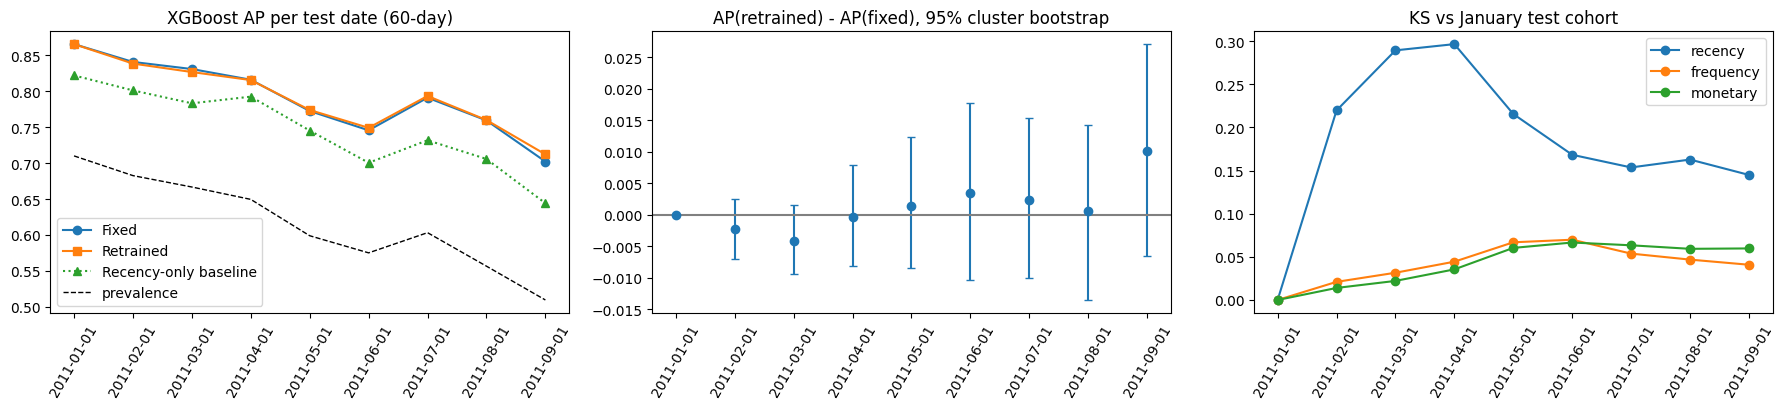

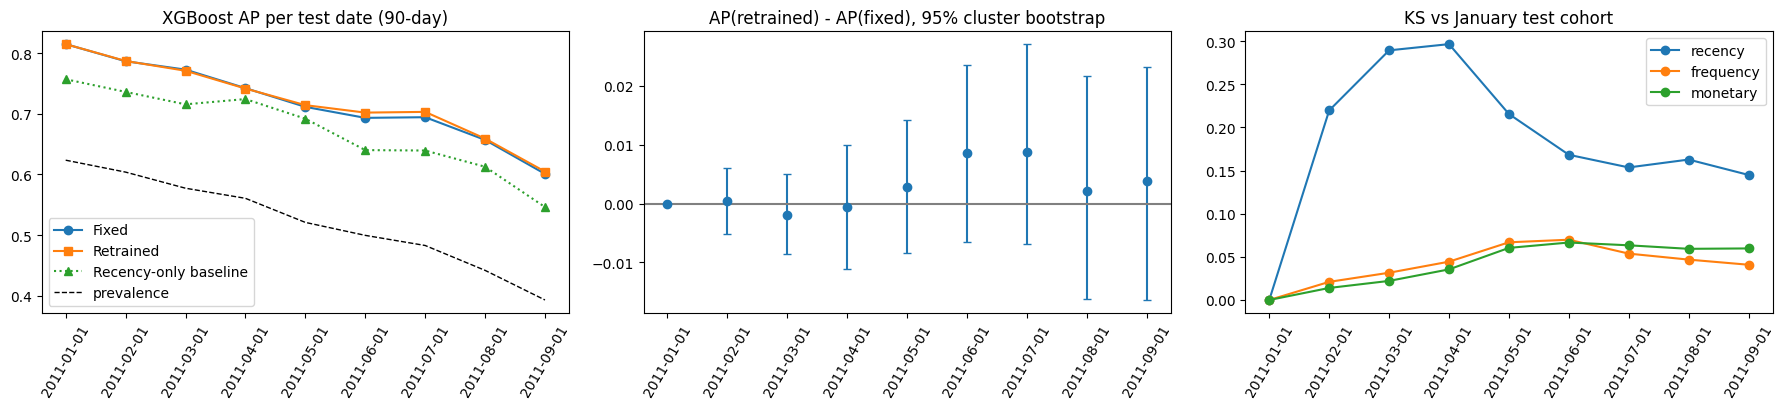

In [13]:
for H, r in [(60, r60), (90, r90)]:
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
    x = r['results']; xs = x[x['model'] == 'XGB']
    for pol, st in [('Fixed', 'o-'), ('Retrained', 's-'), ('Recency-only baseline', '^:')]:
        q = xs[xs['policy'] == pol]; ax[0].plot(q['date'].astype(str), q['AP'], st, label=pol)
    q = xs[xs['policy'] == 'Fixed']; ax[0].plot(q['date'].astype(str), q['prevalence'], 'k--', lw=1, label='prevalence')
    ax[0].set_title(f'XGBoost AP per test date ({H}-day)'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=60)
    g = r['gains'][r['gains']['model'] == 'XGB'].sort_values('date')
    b = r['boot_summary']; b = b[(b['model'] == 'XGB') & b['quantity'].str.match(r'\d{4}-')].set_index('quantity').loc[g['date'].astype(str)]
    ax[1].errorbar(g['date'].astype(str), g['delta_AP'], yerr=[g['delta_AP'] - b['CI_low'].values, b['CI_high'].values - g['delta_AP']], fmt='o', capsize=3)
    ax[1].axhline(0, color='grey'); ax[1].set_title('AP(retrained) - AP(fixed), 95% cluster bootstrap'); ax[1].tick_params(axis='x', rotation=60)
    d = r['drift']
    for f in cc.DRIFT_FEATURES:
        ax[2].plot(d['date'].astype(str), d[f'KS_{f}'], 'o-', label=f)
    ax[2].set_title('KS vs January test cohort'); ax[2].legend(); ax[2].tick_params(axis='x', rotation=60)
    plt.tight_layout(); plt.savefig(f'fig_results_H{H}.png', dpi=200); plt.show()

## STEP 10: save every deliverable and download
Cleaning log, feature dictionary, dated configuration, paired predictions, monthly metrics, bootstrap intervals, drift tables, proposal check and figures.

In [14]:
outputs.save_all('outputs', log, gaps, {60: r60, 90: r90}, check)
!cp fig_results_H*.png outputs/
!zip -qr adaptive_churn_outputs.zip outputs
from google.colab import files
files.download('adaptive_churn_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Check 1 passed: fixed and retrained give identical January predictions (60 and 90 days)
Check 2 passed: every training snapshot has s + H <= fit date (60 and 90 days)


,H,family,policy,fit_date,training_snapshots,train_rows
9,60,XGB,Fixed (common January fit),2011-01-01,"2010-07-01, 2010-08-01, 2010-09-01, 2010-10-01...",14529
10,60,XGB,Retrained,2011-02-01,"2010-08-01, 2010-09-01, 2010-10-01, 2010-11-01...",15251
11,60,XGB,Retrained,2011-03-01,"2010-08-01, 2010-09-01, 2010-10-01, 2010-11-01...",15251
12,60,XGB,Retrained,2011-04-01,"2010-09-01, 2010-10-01, 2010-11-01, 2010-12-01...",15844
13,60,XGB,Retrained,2011-05-01,"2010-11-01, 2010-12-01, 2011-01-01, 2011-02-01...",16811
14,60,XGB,Retrained,2011-06-01,"2010-12-01, 2011-01-01, 2011-02-01, 2011-03-01...",16906
15,60,XGB,Retrained,2011-07-01,"2011-01-01, 2011-02-01, 2011-03-01, 2011-04-01...",16476
16,60,XGB,Retrained,2011-08-01,"2011-02-01, 2011-03-01, 2011-04-01, 2011-05-01...",15720
17,60,XGB,Retrained,2011-09-01,"2011-03-01, 2011-04-01, 2011-05-01, 2011-06-01...",15085
27,90,XGB,Fixed (common January fit),2011-01-01,"2010-06-01, 2010-07-01, 2010-08-01, 2010-09-01...",13989


,step,input_rows,removed_rows,output_rows
0,1. Read both sheets; rename Invoice -> Invoice...,1067371,0,1067371
1,2. Drop rows with missing Customer ID,1067371,243007,824364
2,"3. Drop cancellations (Invoice starts with C),...",824364,18815,805549
3,4. Drop exact duplicate rows,805549,26124,779425
4,Distinct customers kept,<NA>,<NA>,5878
5,Distinct invoices kept,<NA>,<NA>,36969


{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}


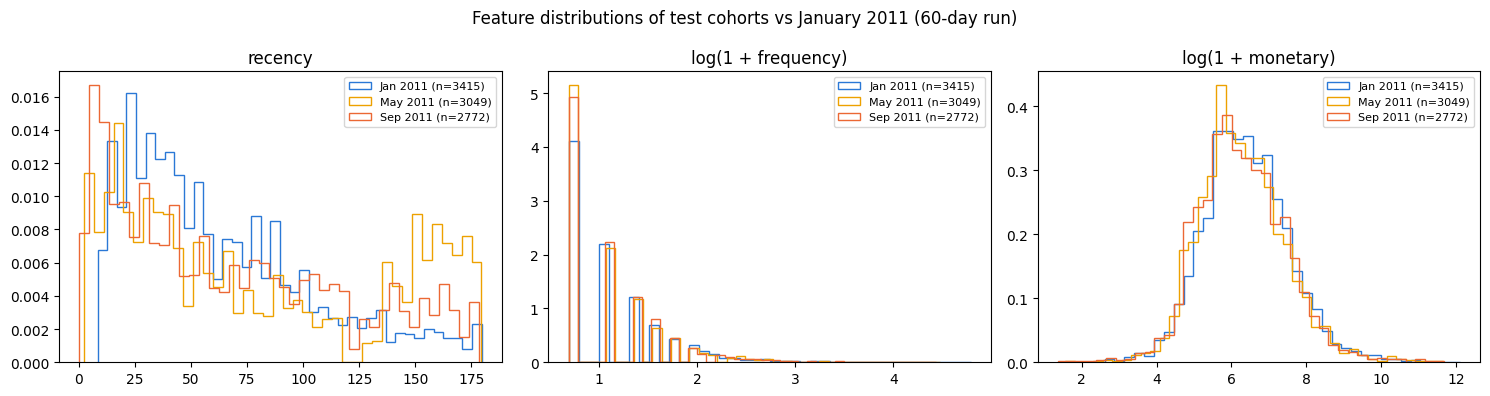

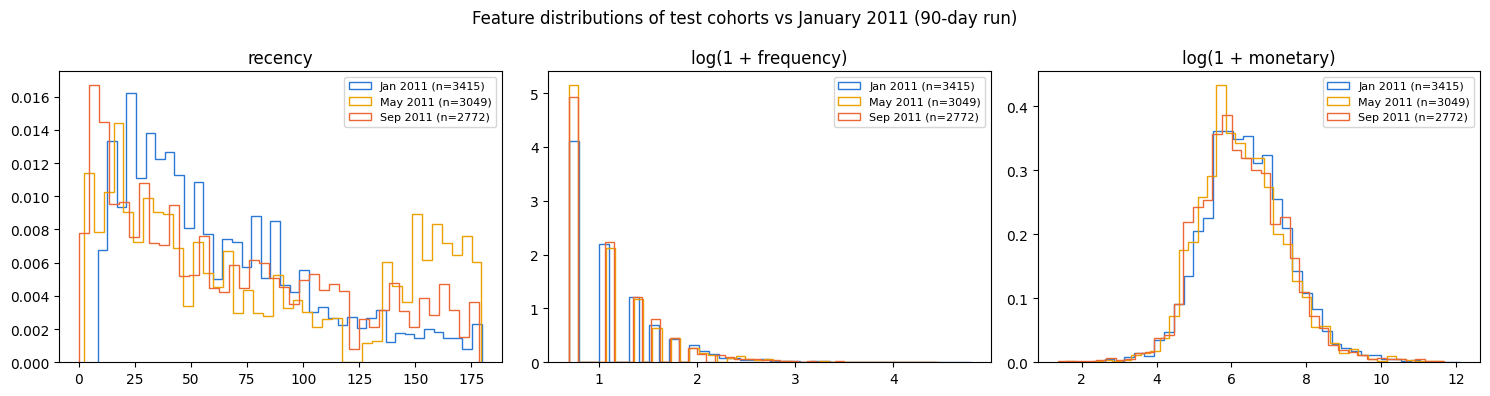

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# ===== STEP 11 (extra): guide checks and extra files. Run after STEP 10 in the same session. =====
import os, json, platform, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, scipy, matplotlib, xgboost

OUT = 'outputs'
os.makedirs(OUT, exist_ok=True)
runs = {60: r60, 90: r90}
T = cc.test_dates()

# 1) The two safety checks from the guide (the cell stops with an error if one fails)
for H, r in runs.items():
    p = r['predictions']
    jan = p[pd.to_datetime(p['date']) == T[0]]
    assert np.array_equal(jan['score_fixed'].values, jan['score_retrained'].values), f'{H}-day: January arms differ'
    for t in T:
        for d in cc.mature(t, r['dates'], H, cc.SETTINGS['WINDOW']):
            assert d + pd.Timedelta(days=H) <= t, f'{H}-day: immature label used for {t.date()}'
print('Check 1 passed: fixed and retrained give identical January predictions (60 and 90 days)')
print('Check 2 passed: every training snapshot has s + H <= fit date (60 and 90 days)')

# 2) Training history: fit date, the 5 snapshot dates and number of rows
hist = []
for H, r in runs.items():
    sn = r['snaps']
    for name in cc.MODELS:
        for t in T:
            used = cc.mature(T[0] if t == T[0] else t, r['dates'], H, cc.SETTINGS['WINDOW'])
            hist.append({'H': H, 'family': name,
                         'policy': 'Fixed (common January fit)' if t == T[0] else 'Retrained',
                         'fit_date': t.date(), 'training_snapshots': ', '.join(f'{d:%Y-%m-%d}' for d in used),
                         'train_rows': int(sn['snapshot'].isin(used).sum())})
hist = pd.DataFrame(hist)
for H in runs:
    hist[hist['H'] == H].to_csv(f'{OUT}/training_history_H{H}.csv', index=False)
display(hist[hist['family'] == 'XGB'])

# 3) Snapshot feature tables with label_end
for H, r in runs.items():
    sn = r['snaps'].copy()
    sn['label_end'] = sn['snapshot'] + pd.Timedelta(days=H)
    sn.to_csv(f'{OUT}/snapshot_features_H{H}.csv', index=False)

# 4) Detailed cleaning log (input / removed / output rows)
v = dict(zip(log['step'], log['rows or customers']))
a, b = v['Raw workbook rows'], v['Remaining identified rows']
c, d = v['Keep non-cancelled lines with quantity and price above zero'], v['Remove exact duplicate retained rows']
clog = pd.DataFrame([
    ['1. Read both sheets; rename Invoice -> InvoiceNo, Price -> UnitPrice, Customer ID -> CustomerID', a, 0, a],
    ['2. Drop rows with missing Customer ID', a, a - b, b],
    ['3. Drop cancellations (Invoice starts with C), Quantity <= 0, UnitPrice <= 0', b, b - c, c],
    ['4. Drop exact duplicate rows', c, c - d, d],
    ['Distinct customers kept', None, None, v['Distinct customers in retained purchases']],
    ['Distinct invoices kept', None, None, v['Distinct invoice identifiers in retained purchases']]],
    columns=['step', 'input_rows', 'removed_rows', 'output_rows'])
clog[['input_rows', 'removed_rows']] = clog[['input_rows', 'removed_rows']].astype('Int64')
clog.to_csv(f'{OUT}/cleaning_log_detailed.csv', index=False)
display(clog)

# 5) Package versions and preprocessing added to the configuration file
cfg_path = f'{OUT}/experiment_config.json'
cfg = json.load(open(cfg_path)) if os.path.exists(cfg_path) else {}
cfg['package_versions'] = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                           'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__,
                           'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__}
cfg['column_mapping'] = {'Invoice': 'InvoiceNo', 'Price': 'UnitPrice', 'Customer ID': 'CustomerID'}
cfg['preprocessing'] = {'LR': 'median imputation -> StandardScaler -> LogisticRegression, fitted on training rows only',
                        'XGB': 'no scaling, NaN handled natively', 'class_weighting': 'none (unweighted)',
                        'threshold': cc.SETTINGS['THRESHOLD']}
json.dump(cfg, open(cfg_path, 'w'), indent=2, default=str)
print(cfg['package_versions'])

# 6) Feature distribution plots: January vs May vs September 2011
for H, r in runs.items():
    sn = r['snaps']; show = [T[0], T[4], T[-1]]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for axi, f in zip(ax, ['recency', 'frequency', 'monetary']):
        for t, col in zip(show, ['#2a78d6', '#eda100', '#eb6834']):
            x = sn.loc[sn['snapshot'] == t, f].astype(float)
            if f != 'recency':
                x = np.log1p(x.clip(lower=0))
            axi.hist(x, bins=40, density=True, histtype='step', lw=1.8, color=col, label=f'{t:%b %Y} (n={len(x)})')
        axi.set_title(f if f == 'recency' else f'log(1 + {f})'); axi.legend(fontsize=8)
    fig.suptitle(f'Feature distributions of test cohorts vs January 2011 ({H}-day run)')
    plt.tight_layout(); plt.savefig(f'{OUT}/feature_distributions_H{H}.png', dpi=150); plt.show()

# 7) Zip everything again and download
if os.path.exists('adaptive_churn_outputs.zip'):
    os.remove('adaptive_churn_outputs.zip')
shutil.make_archive('adaptive_churn_outputs', 'zip', '.', OUT)
from google.colab import files
files.download('adaptive_churn_outputs.zip')


In [16]:
import os, shutil
print(sorted(os.listdir('outputs')))   # check the STEP 11 files are listed
for f in ['fig_results_H60.png', 'fig_results_H90.png']:
    if os.path.exists(f):
        shutil.copy(f, 'outputs/')
shutil.make_archive('FINAL_outputs_all', 'zip', '.', 'outputs')
from google.colab import files
files.download('FINAL_outputs_all.zip')

['boot_summary_H60.csv', 'boot_summary_H90.csv', 'cleaning_log.csv', 'cleaning_log_detailed.csv', 'drift_H60.csv', 'drift_H90.csv', 'endpoint_summary.csv', 'experiment_config.json', 'feature_dictionary.csv', 'feature_distributions_H60.png', 'feature_distributions_H90.png', 'fig_results_H60.png', 'fig_results_H90.png', 'gains_H60.csv', 'gains_H90.csv', 'grid_H60.csv', 'grid_H90.csv', 'plan_H60.csv', 'plan_H90.csv', 'predictions_H60.csv', 'predictions_H90.csv', 'proposal_check.csv', 'purchase_gaps_before_Oct2010.csv', 'results_H60.csv', 'results_H90.csv', 'snapshot_features_H60.csv', 'snapshot_features_H90.csv', 'training_history_H60.csv', 'training_history_H90.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>